In [3]:
import pandas as pd
import matplotlib.pyplot as plt


ATTRIBUTIONS_PATH = "/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/attributions_40_t_career_metric1_v1.csv"
HUMAN_SCORES_PATH = "/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/career_40_t_metric1_v1/human_scores.csv"

attributions_df = pd.read_csv(ATTRIBUTIONS_PATH)


In [4]:
if HUMAN_SCORES_PATH:
    human_df = pd.read_csv(HUMAN_SCORES_PATH)

    merged = pd.merge(
        attributions_df[["example_idx", "position", "token_text", "score"]],
        human_df[["example_idx", "position", "human_score"]],
        on=["example_idx", "position"],
    ).sort_values(["example_idx", "position"]).reset_index(drop=True)

    merged

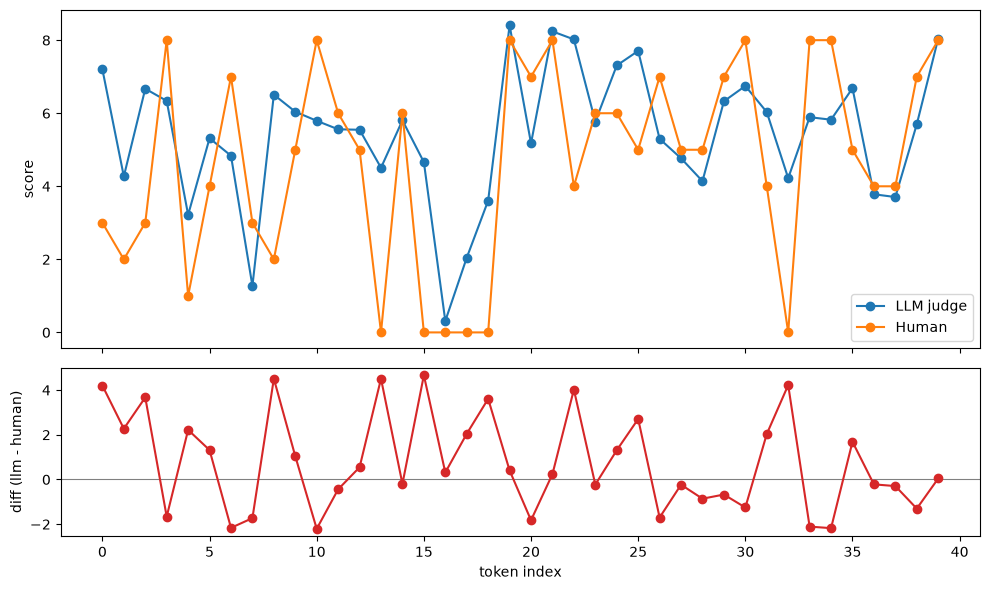

In [5]:

if HUMAN_SCORES_PATH:

    x = range(len(merged))
    diff = merged["score"] - merged["human_score"]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[2, 1])

    ax1.plot(x, merged["score"], marker="o", label="LLM judge")
    ax1.plot(x, merged["human_score"], marker="o", label="Human")
    ax1.set_ylabel("score")
    ax1.legend()

    ax2.axhline(0, color="gray", linewidth=0.8)
    ax2.plot(x, diff, marker="o", color="tab:red")
    ax2.set_ylabel("diff (llm - human)")
    ax2.set_xlabel("token index")

    plt.tight_layout()
    plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(attributions_df["score"].dropna(), bins=20, edgecolor="black")
ax.set_xlabel("LLM judge score")
ax.set_ylabel("count")
ax.set_title("Distribution of LLM judge rubric scores")
plt.tight_layout()
plt.show()